In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# Load cleaned data
train = pd.read_csv("data/train_clean.csv", parse_dates=["date"])
test = pd.read_csv("data/test_clean.csv")

# 0. Helpers

In [3]:
# Revenue per row; returns have negative item_cnt_day, so they reduce revenue
train["revenue"] = train["item_price"] * train["item_cnt_day"]


# Business attributes derived from names
def extract_city(name: str) -> str:
    """City (or channel) from the shop name; check the printed table below."""
    name = name.lstrip("!").strip()
    if name.startswith(("Интернет", "Цифровой")):
        return "Online"
    if name.startswith("Выездная"):
        return "Mobile trade"
    if name.startswith("Сергиев Посад"):
        return "Сергиев Посад"
    return name.split(" ")[0]


for d in (train, test):
    d["city"] = d["shop_name"].map(extract_city)
    d["category_group"] = (
        d["item_category_name"].str.split(" - ").str[0]
    )  # "Игры - PS3" -> "Игры"
train["channel"] = np.where(
    train["city"].isin(["Online", "Mobile trade"]), train["city"], "Offline stores"
)

# Lookups: id -> name
shop_map = train.drop_duplicates("shop_id").set_index("shop_id")["shop_name"]
item_map = train.drop_duplicates("item_id").set_index("item_id")["item_name"]
cat_map = train.drop_duplicates("item_category_id").set_index("item_category_id")[
    "item_category_name"
]


# Helpers
def block_label(b: int) -> str:
    """date_block_num -> 'YYYY-MM' (0 = 2013-01)."""
    return f"{2013 + b // 12}-{b % 12 + 1:02d}"


def short(text, n: int = 40) -> str:
    return text if len(str(text)) <= n else str(text)[: n - 1] + "…"


def barh(s: pd.Series, title: str) -> None:
    """Horizontal bars for a Series with names in the index; the largest value is on top."""
    s = s.sort_values()
    s.rename(index=short).plot.barh(figsize=(10, 0.25 * len(s) + 1.5), title=title)
    plt.show()


def top_share(by: str, value: str = "revenue", n: int = 15) -> pd.DataFrame:
    """Table and chart of the top groups: value, share of total and cumulative share."""
    t = train.groupby(by)[value].sum().sort_values(ascending=False)
    out = pd.DataFrame({value: t, "share_%": t / t.sum() * 100})
    out["cum_share_%"] = out["share_%"].cumsum()
    display(out.head(n).round(1))
    barh(out["share_%"].head(n), f"{by}: share of total {value}, %")
    return out


def growth(by: str, min_prev: float = 0) -> pd.DataFrame:
    """Units sold in the last 12 months vs the previous 12 months, per group (chart: 8 worst and 8 best)."""
    prev = (
        train[train["date_block_num"].between(10, 21)].groupby(by)["item_cnt_day"].sum()
    )
    last = (
        train[train["date_block_num"].between(22, 33)].groupby(by)["item_cnt_day"].sum()
    )
    g = pd.DataFrame({"prev_12m": prev, "last_12m": last}).fillna(0)
    g = g[g["prev_12m"] > min_prev]
    g["change_%"] = (g["last_12m"] / g["prev_12m"] - 1) * 100
    g = g.sort_values("change_%")
    ext = g if len(g) <= 16 else pd.concat([g.head(8), g.tail(8)])
    ext["change_%"].rename(index=short).plot.barh(
        figsize=(10, 0.3 * len(ext) + 1.5),
        color=["tab:red" if v < 0 else "tab:green" for v in ext["change_%"]],
        title=f"{by}: units sold, last 12 months vs previous 12 months, %",
    )
    plt.show()
    return g

# 1. Seasonal-Trend decomposition

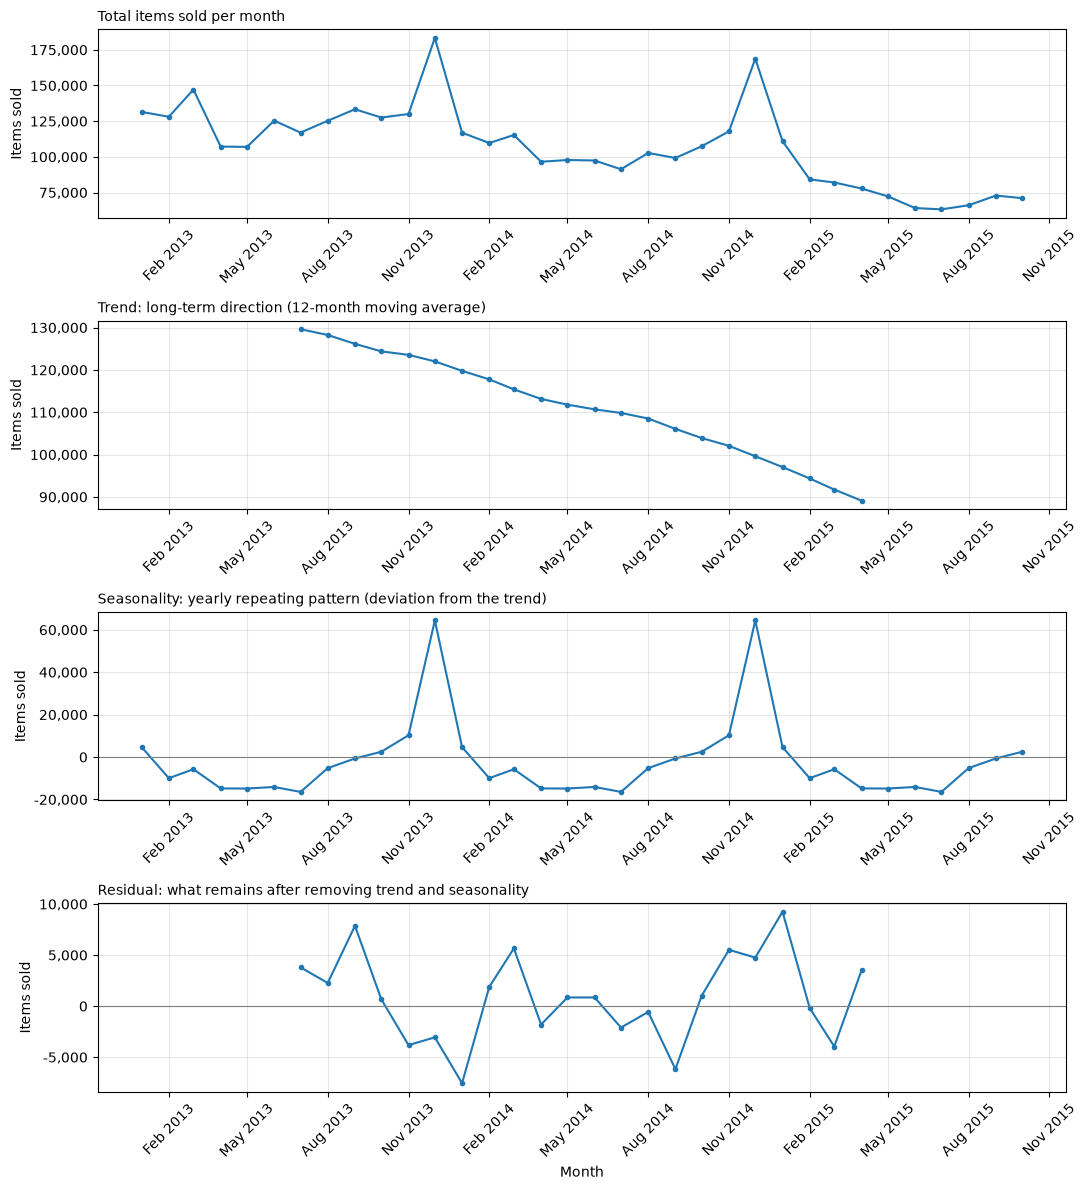

In [4]:
# Total items sold per month, indexed by real dates (block 0 = January 2013)
monthly_units = train.groupby("date_block_num")["item_cnt_day"].sum()
monthly_units.index = pd.date_range("2013-01-01", periods=len(monthly_units), freq="MS")

res = seasonal_decompose(monthly_units, model="additive", period=12)

panels = [
    (res.observed, "Total items sold per month"),
    (res.trend, "Trend: long-term direction (12-month moving average)"),
    (res.seasonal, "Seasonality: yearly repeating pattern (deviation from the trend)"),
    (res.resid, "Residual: what remains after removing trend and seasonality"),
]

fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for ax, (series, title) in zip(axes, panels):
    ax.plot(series, marker="o", markersize=3)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel("Items sold")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
    ax.grid(alpha=0.3)

    # sharex hides tick labels on all but the bottom axis: turn them back on
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)

# Zero reference line where values are deviations, not absolute levels
axes[2].axhline(0, color="gray", lw=0.8)
axes[3].axhline(0, color="gray", lw=0.8)
axes[-1].set_xlabel("Month")

plt.tight_layout()
plt.show()

First, we see a gradually declining trend. Secondly, the highest peak of sales is in December (because of the New Year) with a small peak after (maybe because of 8th of March). Residuals are clearly noise as was expected

# 2. Correlation analysis

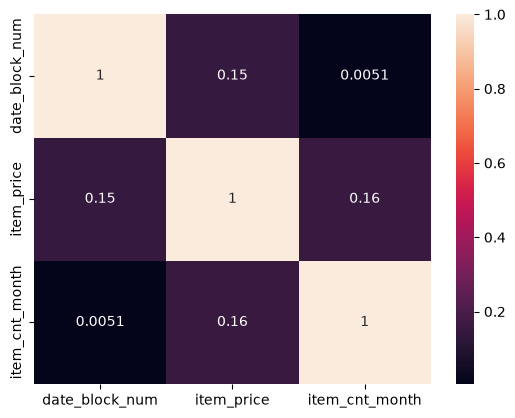

In [5]:
# Monthly target per (month, shop, item): this is what the competition predicts
df = train.groupby(["date_block_num", "shop_id", "item_id"], as_index=False).agg(
    item_cnt_month=("item_cnt_day", "sum"),
    item_price=("item_price", "mean"),
    item_category_id=("item_category_id", "first"),
)
df["year"] = 2013 + df["date_block_num"] // 12
df["month"] = df["date_block_num"] % 12 + 1
# True target is clipped into [0, 20]
df["item_cnt_month"] = df["item_cnt_month"].clip(0, 20)
target = "item_cnt_month"

# Spearman is robust to the heavy skew; IDs are excluded on purpose
sns.heatmap(
    df[["date_block_num", "item_price", target]].corr(method="spearman"), annot=True
)
plt.show()

There is no strong correlation between the numeric features. A weak correlation does not make the features useless: the dependence on time is non-monotonic (seasonality) and is not captured by Spearman correlation.

# 3. Distribution of Numerical Variables

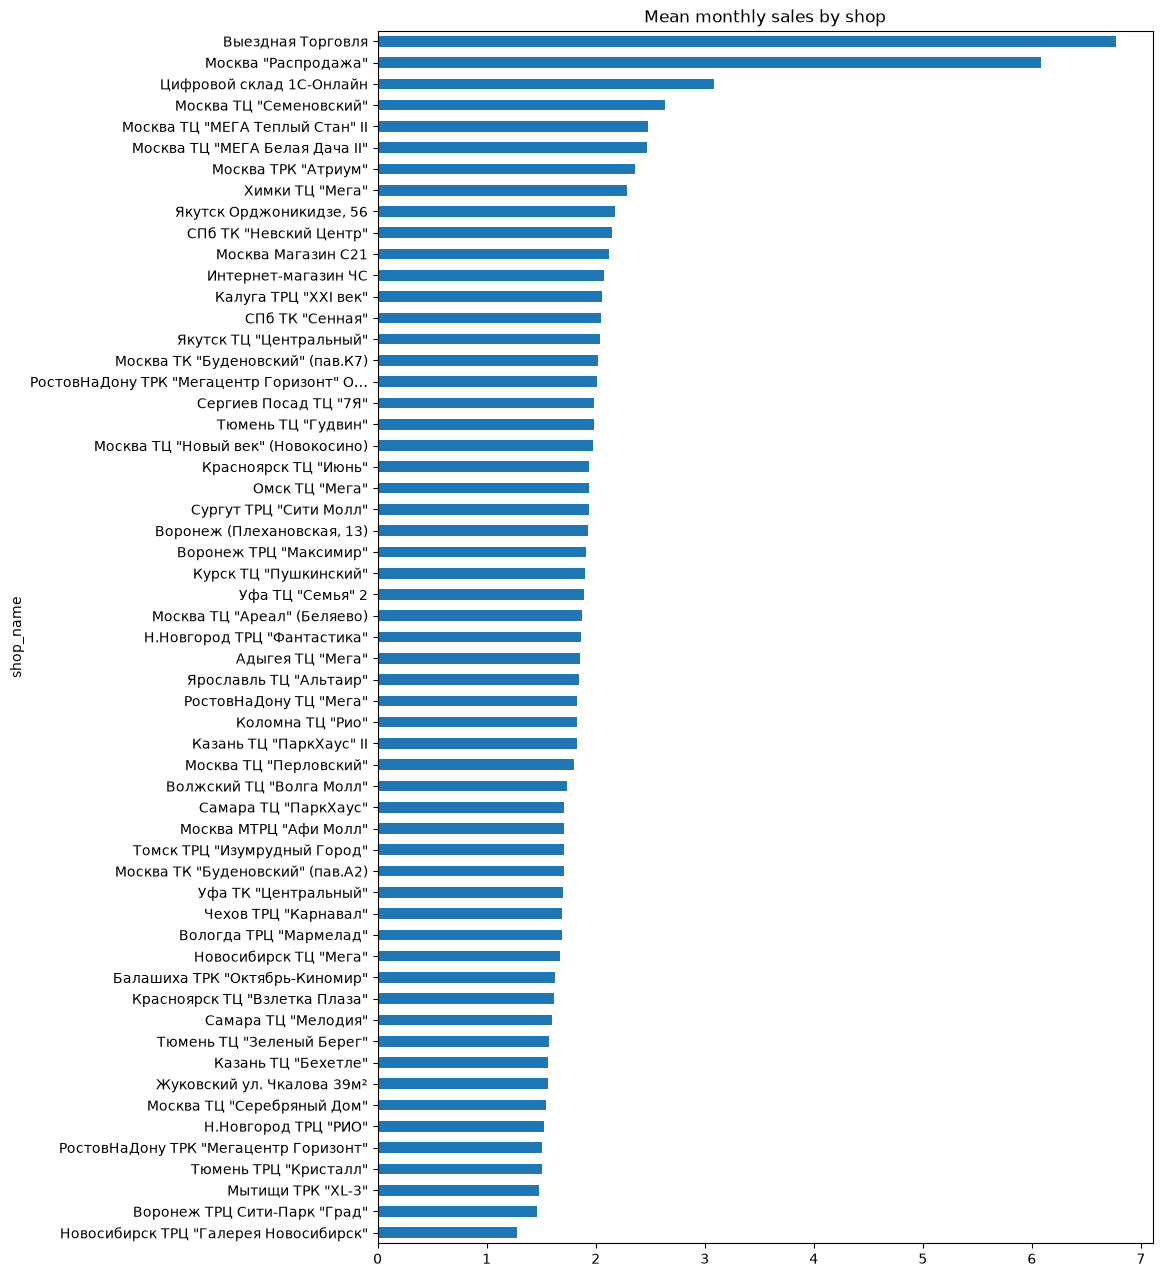

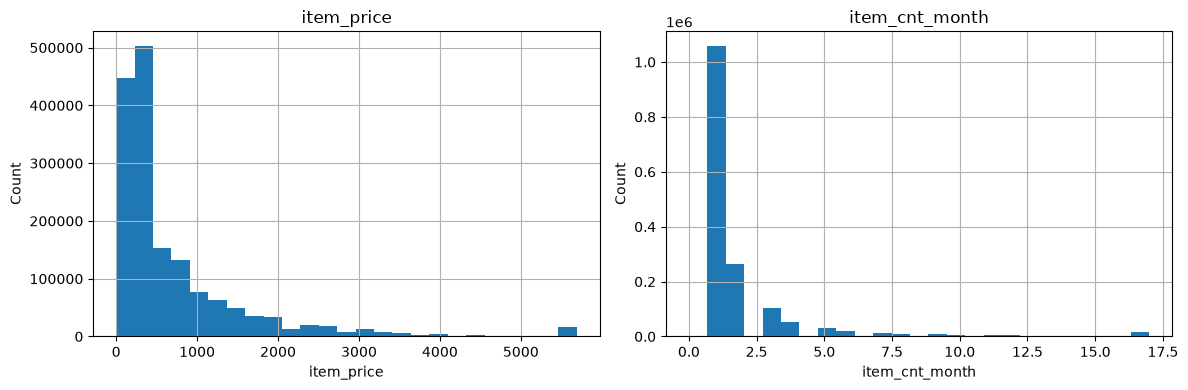

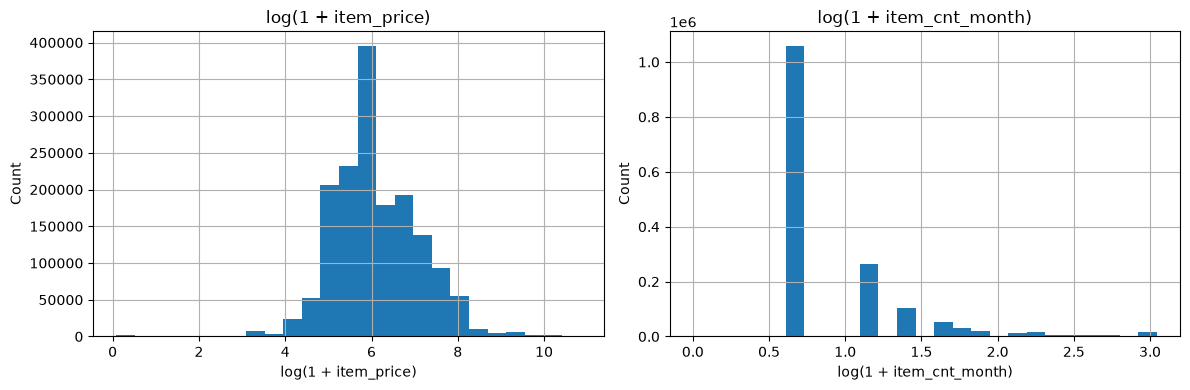

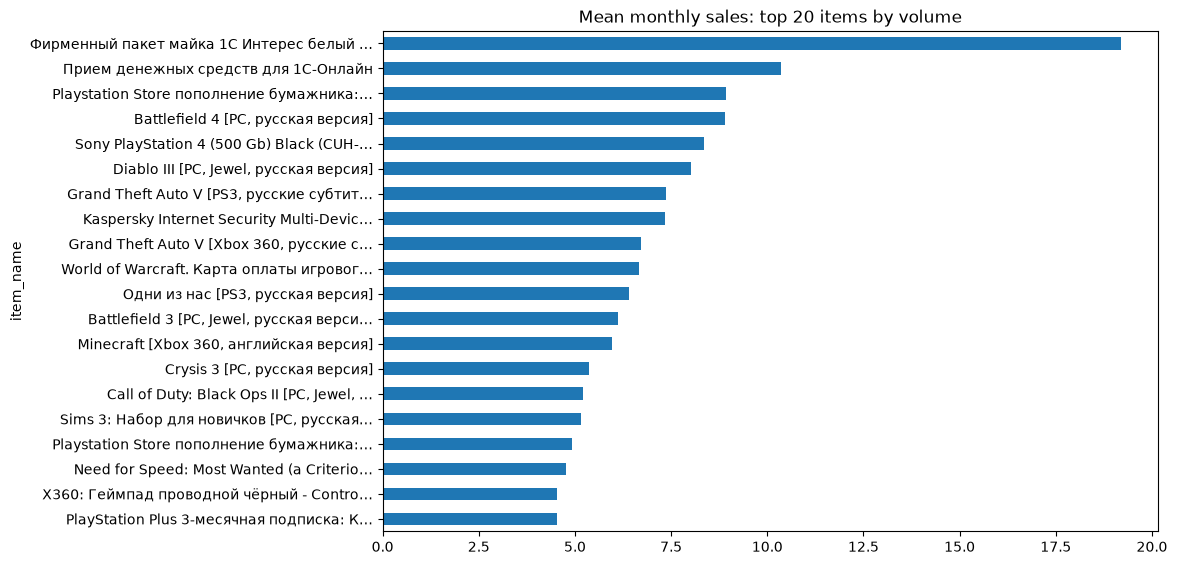

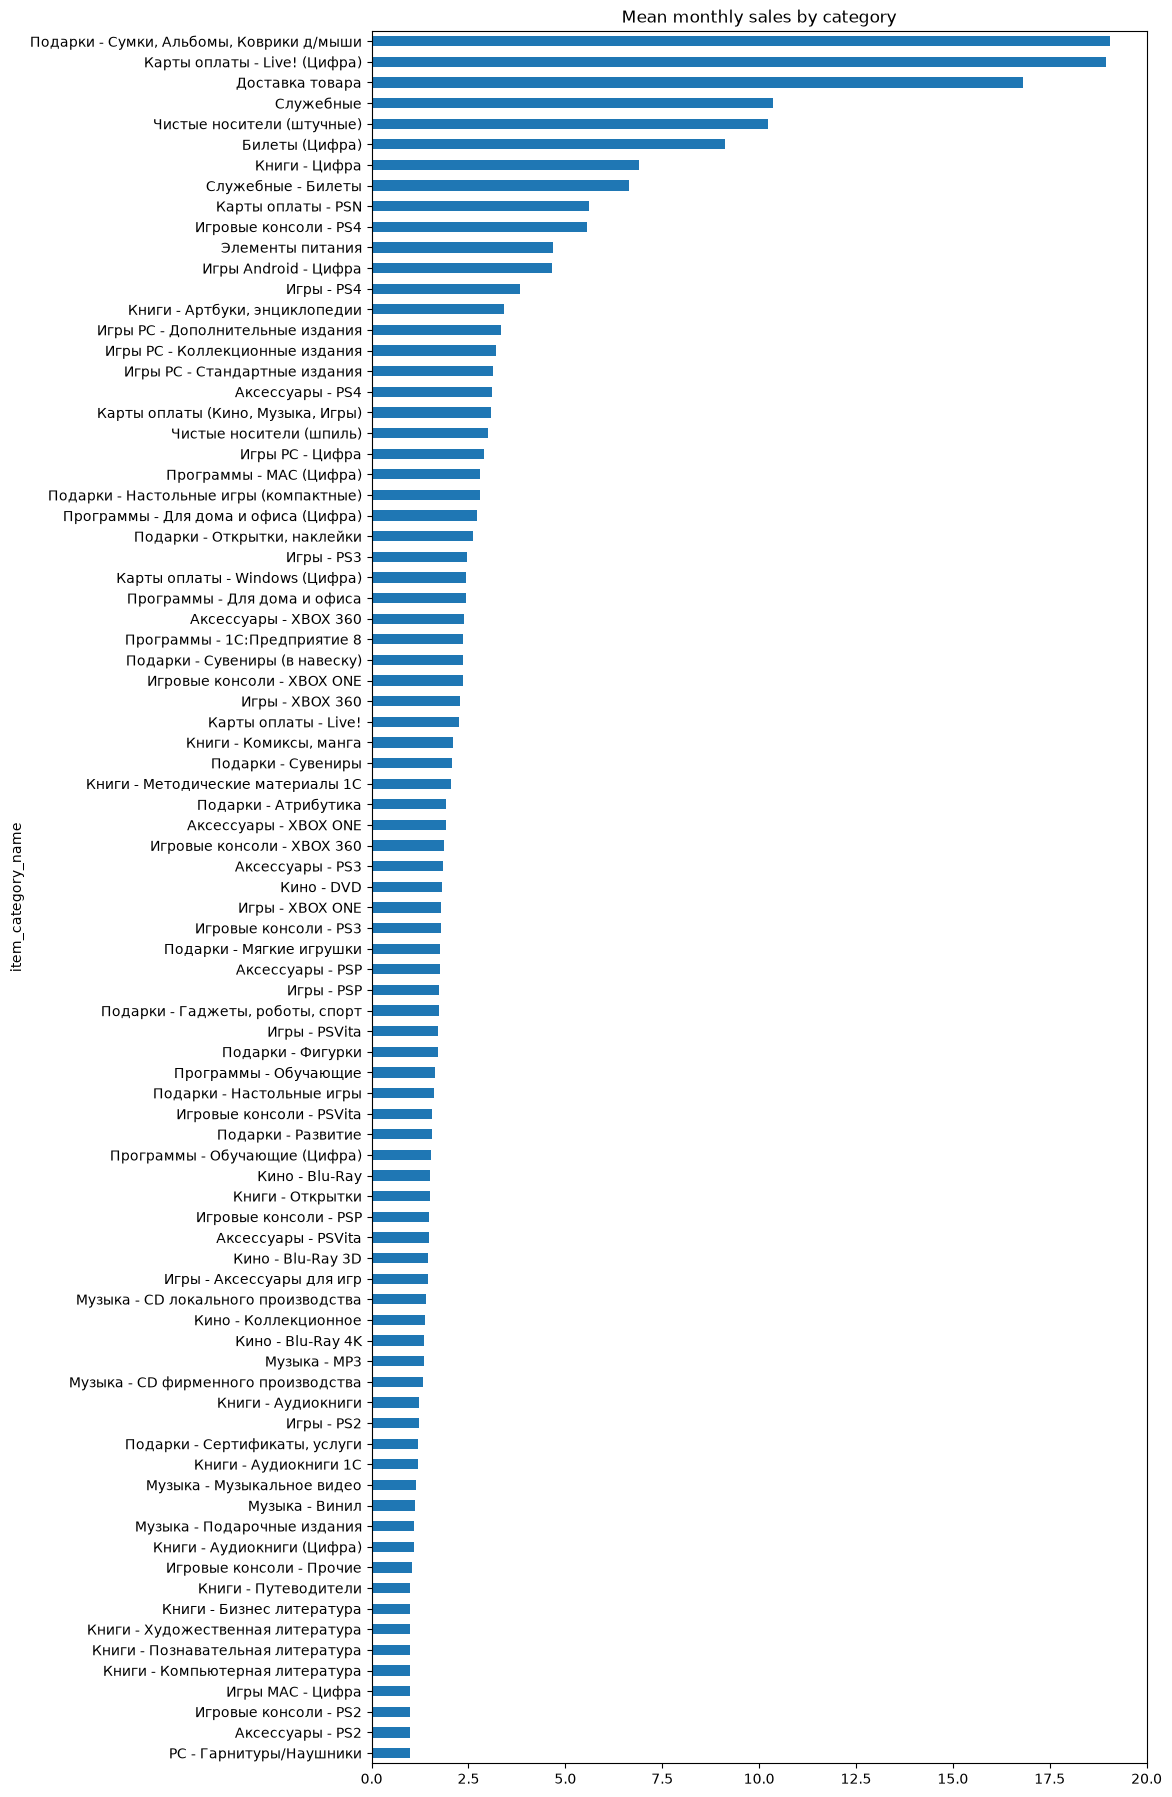

In [6]:
# Names instead of ids
df["shop_name"] = df["shop_id"].map(shop_map)
df["item_name"] = df["item_id"].map(item_map)
df["item_category_name"] = df["item_category_id"].map(cat_map)

barh(df.groupby("shop_name")[target].mean(), "Mean monthly sales by shop")

# Continuous features: histograms (clipped at the 99th percentile for readability)
continuous_feature = ["item_price", target]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, continuous_feature):
    df[feature].clip(upper=df[feature].quantile(0.99)).hist(bins=25, ax=ax)
    ax.set(title=feature, xlabel=feature, ylabel="Count")
plt.tight_layout()
plt.show()

# Log-transformed continuous features: histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, continuous_feature):
    # clip(lower=0) guards against the rare negative price; log1p(0) = 0 is safe
    np.log1p(df[feature].clip(lower=0)).hist(bins=25, ax=ax)
    ax.set(title=f"log(1 + {feature})", xlabel=f"log(1 + {feature})", ylabel="Count")
plt.tight_layout()
plt.show()

# Items: only the 20 best-selling ones (by total volume), grouped by name
top20 = df.groupby("item_name")[target].agg(["sum", "mean"]).nlargest(20, "sum")
barh(top20["mean"], "Mean monthly sales: top 20 items by volume")

barh(df.groupby("item_category_name")[target].mean(), "Mean monthly sales by category")

- **Shops.** For most shops the mean monthly sales per active shop-item pair are similar (about 1.3–2.6 units). Three shops stand out: "Выездная Торговля" (6.8), "Москва "Распродажа" (6.1) and "Цифровой склад 1С-Онлайн" (3.1). All three are non-standard formats (off-site trade, a sale point, a digital warehouse). 
- **item_price** is right-skewed: the mode is at about 200–450 and the tail is long (the last bar collects everything above the 99th percentile). After `log(1 + price)` the distribution is bell-shaped and roughly symmetric, so the price is close to log-normal. There are a few near-zero prices on the left.
  
- **item_cnt_month** roughly two thirds of shops have exactly 1 unit, and the right tail decays quickly (geometric-like). The log transformation does not help because the values stay discrete and concentrated
  
- **Items.** Among the 20 best-selling items the mean monthly sales per pair are mostly 4.5–10. Only «Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм» is close to the cap (≈19): a low-value item sold in bulk. After clipping at 20, «Доставка до пункта выдачи (Boxberry)» (item 11373) no longer stands out in this top 20.
  
- **Categories.** Most categories sell 1–3 units per pair. The highest means are: Подарки - Сумки, Альбомы, Коврики д/мыши (≈19), Карты оплаты (≈19), Доставка товара (≈17), Служебные (≈10), Чистые носители (≈10) and Билеты (Цифра) (≈9). The categories are service-like or low-value goods sold in large quantities (delivery, service items, digital tickets, gifts such as bags), and their means are close to the cap of 20.


# 4. Data volume over time

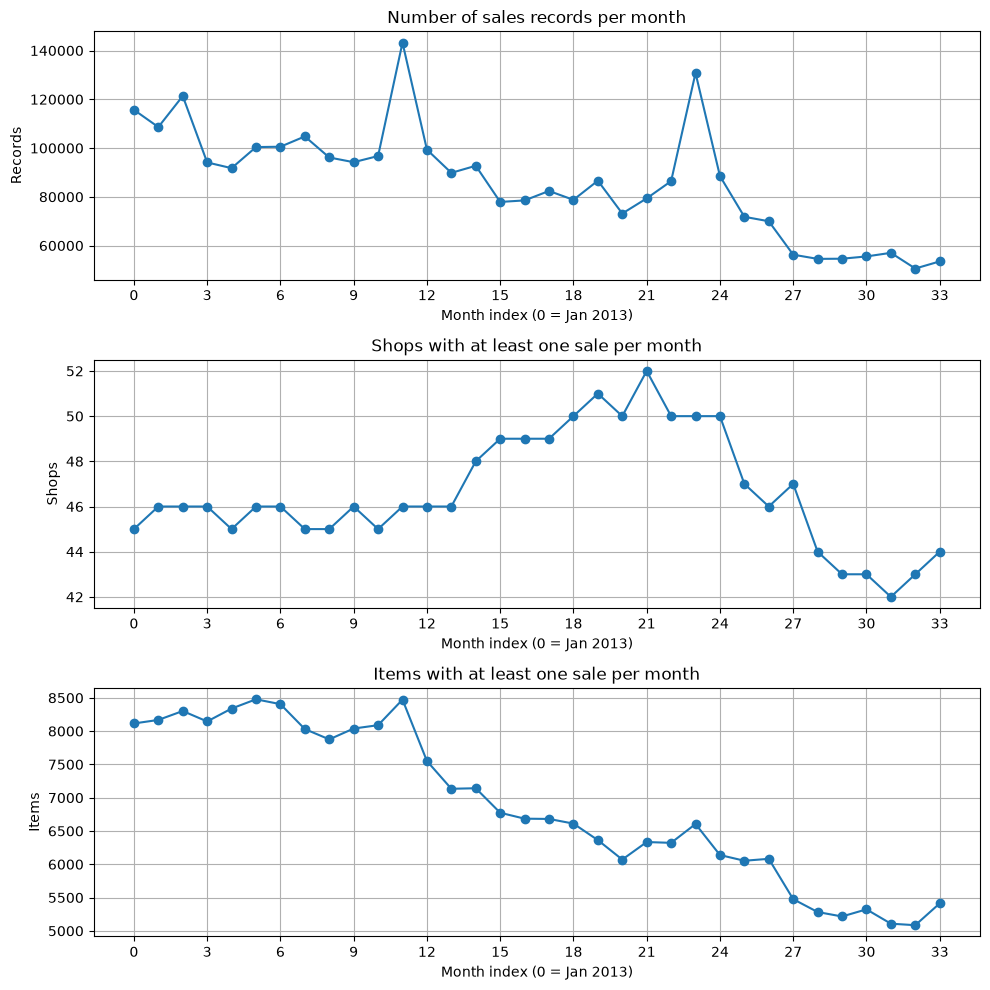

In [7]:
# Data volume per month: rows, active shops, active items
volume = train.groupby("date_block_num").agg(
    rows=("item_id", "size"),
    active_shops=("shop_id", "nunique"),
    active_items=("item_id", "nunique"),
)

panels = [
    ("rows", "Number of sales records per month", "Records"),
    ("active_shops", "Shops with at least one sale per month", "Shops"),
    ("active_items", "Items with at least one sale per month", "Items"),
]

fig, axes = plt.subplots(3, 1, figsize=(10, 10))
for ax, (col, title, ylabel) in zip(axes, panels):
    ax.plot(volume.index, volume[col], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Month index (0 = Jan 2013)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, len(volume), 3))
    ax.grid(True)
plt.tight_layout()
plt.show()

Over time, the number of sales records halves (with December peaks), active items fall from ~8,100 to ~5,400, and active shops vary between 42 and 52. The decline comes from a narrowing assortment (items per shop fall to ~50%). The data is not stationary, so a time-based validation split is needed

# 5. Shops, cities and channels

## 5.1 Online, mobile trade and offline stores

channel,Mobile trade,Offline stores,Online
year,,,
2013,0.5,96.6,2.9
2014,0.5,95.0,4.5
2015,0.5,91.6,7.9


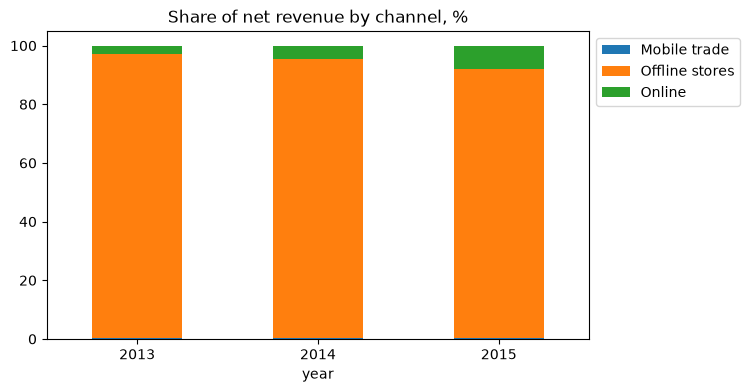

In [8]:
# Share of net revenue by channel and year, %
channel_mix = (
    pd.crosstab(
        train["year"],
        train["channel"],
        values=train["revenue"],
        aggfunc="sum",
        normalize="index",
    )
    * 100
)
display(channel_mix.round(1))
channel_mix.plot.bar(
    stacked=True, figsize=(7, 4), rot=0, title="Share of net revenue by channel, %"
)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- Offline stores bring most of the net revenue, but their share falls from 96.6% (2013) to 91.6% (2015, January–October), while the online share grows from 2.9% to 7.9%. Mobile trade is stable at about 0.5%.
- Online is still small, but it is the only growing channel, so its shops matter more for the latest months than for the whole history.

## 5.2 Closed and opened shops

In [9]:
shops_life = train.groupby("shop_name").agg(
    units=("item_cnt_day", "sum"),
    revenue=("revenue", "sum"),
    first_block=("date_block_num", "min"),
    last_block=("date_block_num", "max"),
)
shops_life["first_sale"] = shops_life["first_block"].map(block_label)
shops_life["last_sale"] = shops_life["last_block"].map(block_label)

shops_life["revenue_mln"] = shops_life["revenue"] / 1e6
show = ["units", "revenue_mln", "first_sale", "last_sale"]

print("Stopped selling before Oct 2015:")
display(
    shops_life[shops_life["last_block"] < 33].sort_values("last_block")[show].round(1)
)
print("Started selling after Jan 2013:")
display(
    shops_life[shops_life["first_block"] > 0].sort_values("first_block")[show].round(1)
)

# How much of the history belongs to shops we have to forecast
in_test = train["shop_id"].isin(test["shop_id"])
print(
    f"Shops in test: {test['shop_id'].nunique()} of {train['shop_id'].nunique()}; "
    f"they give {train.loc[in_test, 'revenue'].sum() / train['revenue'].sum():.1%} of historical revenue"
)

Stopped selling before Oct 2015:


,units,revenue_mln,first_sale,last_sale
shop_name,,,,
"Воронеж ТРЦ Сити-Парк ""Град""",3595.0,2.3,2013-01,2013-04
"Москва ТК ""Буденовский"" (пав.А2)",7705.0,5.6,2013-01,2013-04
"Москва ТЦ ""Серебряный Дом""",8780.0,5.8,2013-01,2013-07
"Казань ТЦ ""Бехетле""",19763.0,6.0,2013-01,2014-08
"Красноярск ТЦ ""Взлетка Плаза""",25838.0,27.8,2013-06,2015-01
"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",4943.0,4.3,2014-03,2015-01
"СПб ТК ""Сенная""",50608.0,62.2,2013-01,2015-01
"Москва ТЦ ""Перловский""",60828.0,46.7,2013-01,2015-02
"Мытищи ТРК ""XL-3""",5482.0,5.9,2014-08,2015-04


Started selling after Jan 2013:


,units,revenue_mln,first_sale,last_sale
shop_name,,,,
"Вологда ТРЦ ""Мармелад""",42762.0,38.2,2013-02,2015-10
Цифровой склад 1С-Онлайн,63388.0,49.8,2013-05,2015-10
"Красноярск ТЦ ""Взлетка Плаза""",25838.0,27.8,2013-06,2015-01
Выездная Торговля,15866.0,16.4,2013-10,2015-10
"Тюмень ТРЦ ""Кристалл""",17090.0,20.1,2013-12,2015-10
"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",4943.0,4.3,2014-03,2015-01
"РостовНаДону ТРК ""Мегацентр Горизонт""",16617.0,18.1,2014-03,2015-10
"Томск ТРЦ ""Изумрудный Город""",24909.0,27.7,2014-04,2015-10
"Н.Новгород ТРЦ ""РИО""",6451.0,8.6,2014-07,2015-10


Shops in test: 42 of 57; they give 83.7% of historical revenue


In [11]:
# Closed shops: are they in the test set?
closed = shops_life[shops_life["last_block"] < 33].copy()
closed["in_test"] = closed.index.isin(test["shop_name"])
print(f"Closed shops that are in test: {closed['in_test'].sum()} of {len(closed)}")
display(
    closed.sort_values("last_block")[["last_sale", "revenue_mln", "in_test"]].round(1)
)

Closed shops that are in test: 0 of 13


,last_sale,revenue_mln,in_test
shop_name,,,
"Воронеж ТРЦ Сити-Парк ""Град""",2013-04,2.3,False
"Москва ТК ""Буденовский"" (пав.А2)",2013-04,5.6,False
"Москва ТЦ ""Серебряный Дом""",2013-07,5.8,False
"Казань ТЦ ""Бехетле""",2014-08,6.0,False
"Красноярск ТЦ ""Взлетка Плаза""",2015-01,27.8,False
"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",2015-01,4.3,False
"СПб ТК ""Сенная""",2015-01,62.2,False
"Москва ТЦ ""Перловский""",2015-02,46.7,False
"Мытищи ТРК ""XL-3""",2015-04,5.9,False


- 13 shops stopped selling before October 2015 (3 in 2013, 1 in 2014, 9 in January–September 2015) and 12 shops started after January 2013 (3 of them opened and closed within the data).
- Новосибирск ТРЦ "Галерея Новосибирск" opened in October 2015 and has only one month of history (330 units); if it is in test, it is a cold-start shop.
- Closed shops aren't in the test dataset, therefore there is no need to create a new feature for old and new shops

## 5.3 Who is growing and who is declining

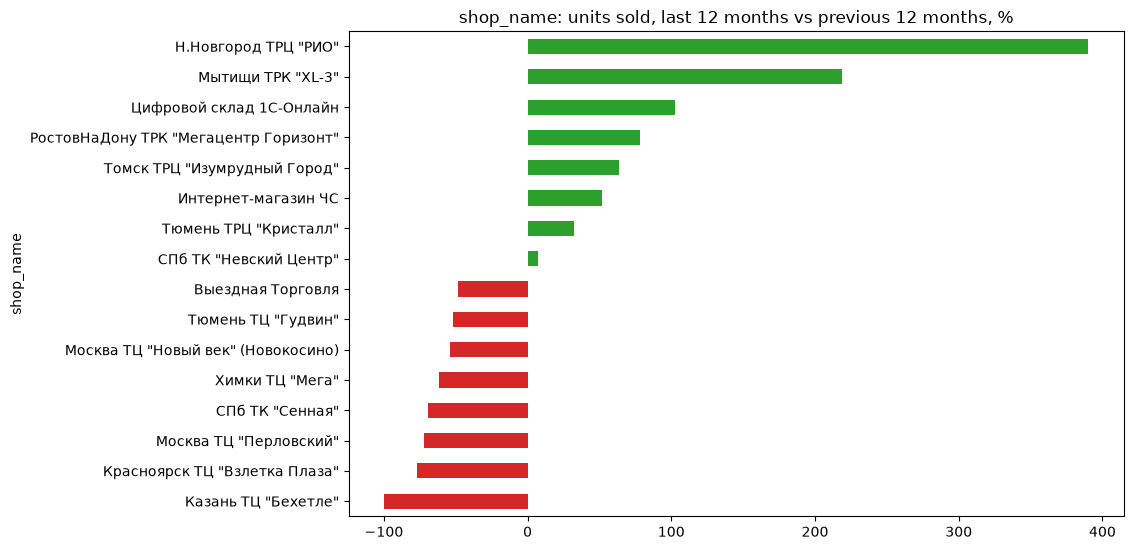

In [16]:
g_shops = growth("shop_name", min_prev=1000)

- Online shops grow while being open for the whole period: Цифровой склад 1С-Онлайн about +100% and Интернет-магазин ЧС about +50% in units (last 12 months vs previous 12). This agrees with the rising online share in 5.1.
- Выездная Торговля (about −48%) and the offline shop Тюмень ТЦ "Гудвин" (about −52%) lost about half of their units, although both were open the whole time.
- The other extreme bars mostly show openings and closings, not demand. The biggest drops are closed shops (Казань ТЦ "Бехетле" −100%, Красноярск ТЦ "Взлетка Плаза", Москва ТЦ "Перловский", СПб ТК "Сенная"), and the biggest gains are shops opened inside the comparison period (Н.Новгород ТРЦ "РИО" about +390%, Мытищи ТРК "XL-3" about +220%), which are compared with a mostly empty previous period.

# 6. Categories and items

## 6.1 Category structure

,revenue,share_%,cum_share_%
category_group,,,
Игры,1.153847e+09,34.0,34.0
Игровые консоли,5.280281e+08,15.5,49.5
Игры PC,4.779817e+08,14.1,63.6
Кино,3.349880e+08,9.9,73.4
Подарки,3.091466e+08,9.1,82.5
Аксессуары,1.663868e+08,4.9,87.4
Музыка,1.497200e+08,4.4,91.8
Программы,1.220829e+08,3.6,95.4
Карты оплаты,6.624700e+07,1.9,97.3


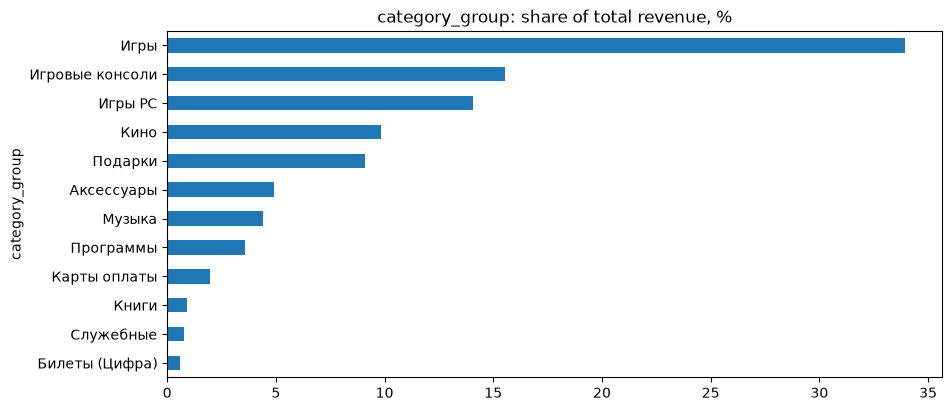

,revenue,share_%,cum_share_%
item_category_name,,,
Игры - PS3,412050281.9,12.1,12.1
Игры - PS4,373010312.1,11.0,23.1
Игровые консоли - PS4,292239761.8,8.6,31.7
Игры - XBOX 360,259619128.4,7.6,39.3
Игры PC - Стандартные издания,257519291.1,7.6,46.9
Кино - DVD,169944221.7,5.0,51.9
Игры PC - Дополнительные издания,136419148.6,4.0,55.9
Музыка - CD локального производства,100022563.6,2.9,58.9
Кино - Blu-Ray,90478731.8,2.7,61.5


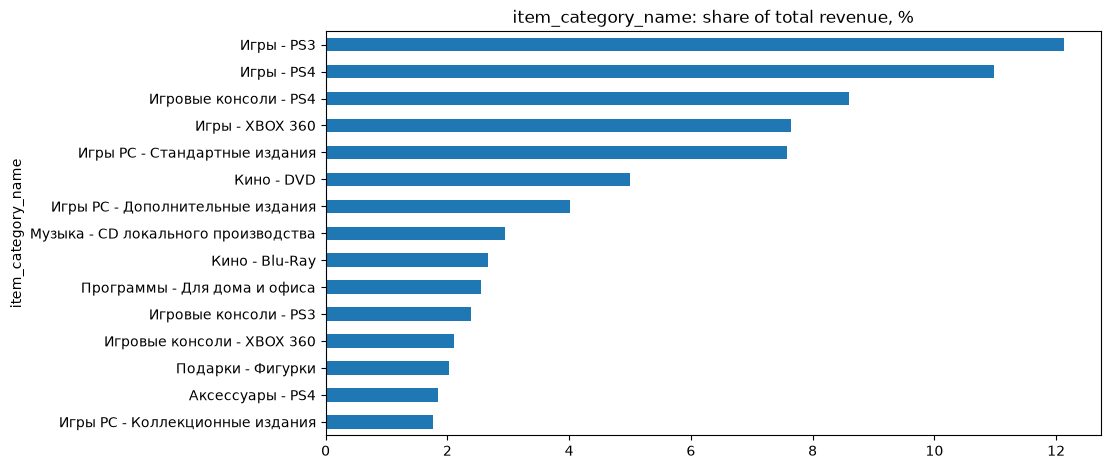

In [17]:
group_rev = top_share("category_group", n=12)
cat_rev = top_share("item_category_name")

- Revenue is concentrated in a few groups: Игры (34.0%), Игровые консоли (15.5%) and Игры PC (14.1%) give 63.6% of net revenue; with Кино (9.9%) and Подарки (9.1%) the top 5 groups give 82.5%.
- At category level the top is also gaming: Игры - PS3 (12.1%), Игры - PS4 (11.0%), Игровые консоли - PS4 (8.6%), Игры - XBOX 360 (7.6%) and Игры PC - Стандартные издания (7.6%); the top 15 categories give 74.2%. Both PS3 and PS4 are in the top, so the console cycle matters and the trends of the two generations should be checked separately.
- Categories with the highest monthly sales per pair in section 3 bring little revenue: Карты оплаты (1.9%), Служебные (0.8%) and Билеты (Цифра) (0.6%), about 3% together.

# 7. New items in test dataset

In [19]:
# Segments of test rows by how much history exists
all_items = set(train["item_id"])
recent_items = set(train.loc[train["date_block_num"] >= 22, "item_id"])
known_pairs = pd.MultiIndex.from_frame(train[["shop_id", "item_id"]].drop_duplicates())
test_pairs = pd.MultiIndex.from_frame(test[["shop_id", "item_id"]])

test["segment"] = np.select(
    [
        ~test["item_id"].isin(all_items),
        ~test["item_id"].isin(recent_items),
        ~test_pairs.isin(known_pairs),
    ],
    [
        "1. new item (never in train)",
        "2. item not sold in last 12 months",
        "3. known item, new shop-item pair",
    ],
    default="4. known pair",
)

# Rows and share of the test set per segment
seg = test["segment"].value_counts().sort_index()
print(pd.DataFrame({"rows": seg, "share_%": (seg / seg.sum() * 100).round(1)}))

                                      rows  share_%
segment                                            
1. new item (never in train)         15246      7.1
2. item not sold in last 12 months    3696      1.7
3. known item, new shop-item pair    85032     39.7
4. known pair                       110226     51.5


Only about half of the test rows (51.5%) are shop-item pairs that the model has seen in train. For the other half, the model has no sales history of that exact pair. Most of them (39.7%) are items that are known but were never sold in that particular shop. Brand-new items are rare (7.1%), and items that stopped selling are even rarer (1.7%).

So the main difficulty is not new products, but known products in new shops. For these, the model has to rely on how the item sells in other shops and how the shop sells in general.


# Conclusion

**What the data shows**
- **Trend and seasonality.** Total sales decline over time, with a strong December peak (New Year) and a small peak in spring. The residual is noise.
- **Shrinking assortment.** The number of sales records halves, and the number of items with at least one sale per month falls from about 8,100 to about 5,400. Active shops stay between 42 and 52, so the decline comes from the narrowing assortment, not from fewer shops.
- **Unstable set of shops.** 13 shops stopped selling before October 2015 (9 of them in 2015) and 12 opened after January 2013. 
- **Channels.** Offline stores give most of the revenue, but their share falls from 96.6% to 91.6%, while the online share grows from 2.9% to 7.9%.
- **Concentration.** Gaming (games, consoles, PC games) gives 63.6% of net revenue, and the top 5 category groups give 82.5%.
- **Target.** `item_cnt_month` is a discrete count, about two thirds of values equal 1, and the tail is clipped at 20. `item_price` is right-skewed and close to log-normal.
- **Special cases.** Service-like and cheap items (delivery, payment cards, service items, digital tickets, gift bags) and non-standard shops (off-site trade, a sale point, a digital warehouse) have the highest mean sales per pair, close to the cap, but bring only a small share of revenue.
- **Correlations.** Price and time have no strong monotonic relation with the target. This does not make them useless, because seasonality is not captured by Spearman correlation.

**What it means for modeling**
- The data is not stationary, so validation must be time-based (train on earlier months, validate on the latest ones), never random.
- Recent months are the most relevant for November 2015. Use lag and rolling features and give recent history more weight.
- Shop and category features should be kept (target encoding only from past months), with flags for service items and non-standard shops, and calendar features for seasonality.
